In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [7]:
# 1. Δημιουργία realistic dataset (Πρόβλεψη Churn Πελατών)
np.random.seed(100)
n_samples = 500

tenure = np.random.randint(1, 60, size=n_samples)          # Μήνες παραμονής
monthly_charges = np.random.uniform(20, 120, size=n_samples) # Μηνιαίο κόστος (€)
support_calls = np.random.randint(0, 10, size=n_samples)    # Κλήσεις στην υποστήριξη

# Πιθανότητα αποχώρησης (Churn = 1)
churn_score = (support_calls * 0.4) + (monthly_charges * 0.02) - (tenure * 0.05)
churn_prob = 1 / (1 + np.exp(-churn_score))
churn = (churn_prob > 0.5).astype(int)

df_churn = pd.DataFrame({
    "Tenure_Months": tenure,
    "Monthly_Charges": monthly_charges,
    "Support_Calls": support_calls,
    "Churn": churn
    })

In [8]:
df_churn.head(5)

    

,Tenure_Months,Monthly_Charges,Support_Calls,Churn
0,9,58.634079,4,1
1,25,79.088079,5,1
2,4,33.752361,3,1
3,40,100.827041,5,1
4,24,116.582582,4,1


In [9]:
X = df_churn[["Tenure_Months", "Monthly_Charges", "Support_Calls"]]
y = df_churn["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)
}

results = []

In [11]:
# Loop για εκπαίδευση & αξιολόγηση κάθε μοντέλου
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 3),
        "Precision": round(prec, 3),
        "Recall": round(rec, 3),
        "F1-Score": round(f1, 3)
    })

df_results = pd.DataFrame(results)
print("--- MODEL COMPARISON REPORT ---")
print(df_results.to_string(index=False))


--- MODEL COMPARISON REPORT ---
              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression      0.99      1.000   0.989     0.994
      Decision Tree      0.90      0.953   0.931     0.942
      Random Forest      0.95      0.946   1.000     0.972


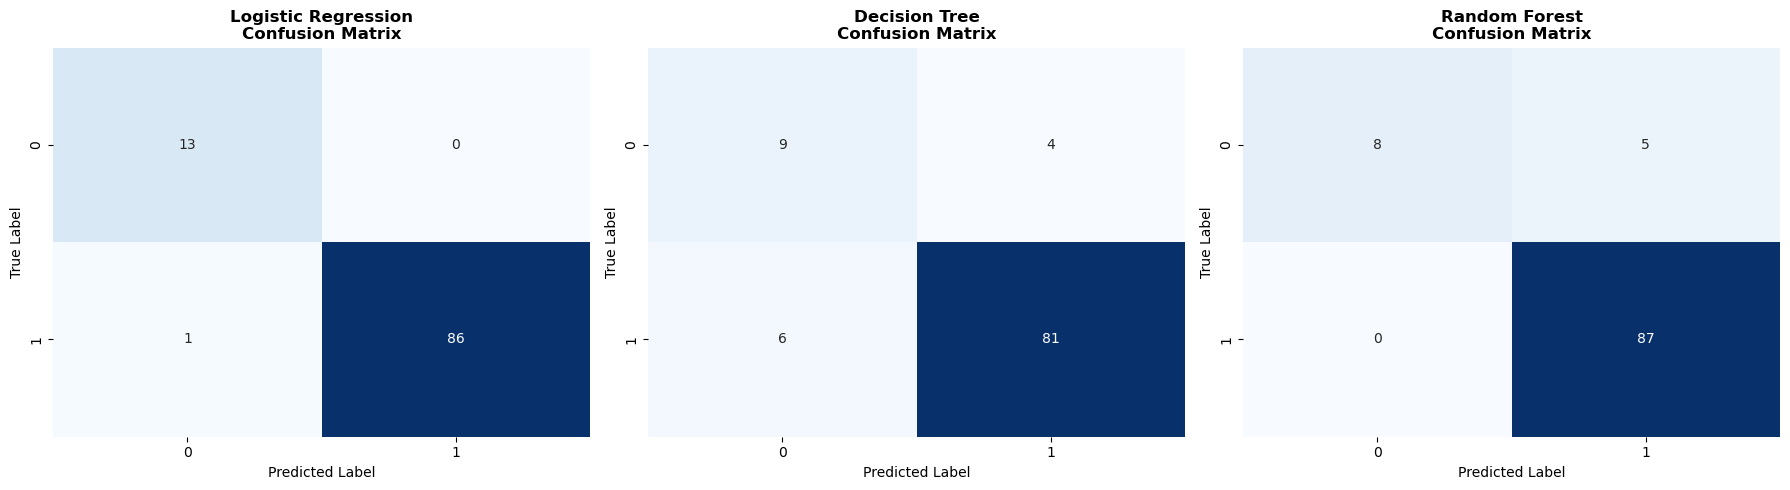

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i], cbar=False)
    axes[i].set_title(f"{name}\nConfusion Matrix", fontweight="bold")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

plt.tight_layout()
plt.savefig("ml_model_comparison_2026.png", dpi=300)
plt.show()